# Alerta Criadouro - Rede Neural LSTM: casos de dengue das próximas 4 semanas

**Global Solution 2026.2 - FIAP - Tecnólogo em Inteligência Artificial - turma 1TIAPZ**
**Matéria:** Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos

| Integrante | RM |
|---|---|
| Matheus Rebelo | 570260 |
| Felipe Olmos | 570946 |
| Luiz Guilherme | 573486 |

Repositório: https://github.com/matheusrebelo04-maker/alerta-criadouro

## 1. Problema e aplicação

Cerca de 75% dos focos do mosquito da dengue ficam dentro das casas (governo de SP, via Poder360, fev/2026). Em 2024 o Brasil teve o pior ano da história, com 6,48 milhões de casos prováveis. A larva vira mosquito em uns 10 dias, e a família quase sempre só percebe quando alguém adoece.

**Público:** famílias que moram em casas com quintal em bairros da cidade de São Paulo, usuárias do Alerta Criadouro (aparelho com ESP32 que avisa quando o potinho sentinela do quintal está com água parada há dias).

**Papel da rede neural:** o modelo de Machine Learning do projeto diz se a próxima semana vai ser de risco alto. A rede neural vai um passo além: **prevê quantos casos de dengue a cidade vai ter em cada uma das próximas 4 semanas**. Com isso o app mostra a tendência (subindo ou caindo) e a família, os agentes de saúde e a prefeitura sabem com um mês de antecedência se vem um pico.

- **Entrada:** as últimas 12 semanas de dados da cidade (variação dos casos, Rt, temperatura, umidade e época do ano).
- **Saída:** o número de casos previsto para cada uma das 4 semanas seguintes.

É uma tarefa de **regressão em série temporal**, diferente da classificação feita em Machine Learning.

## 2. Base de dados

**Fonte:** InfoDengue (Fiocruz e FGV), que junta as notificações de dengue do SINAN com dados de clima. Dados semanais da cidade de São Paulo (código IBGE 3550308), de janeiro de 2015 a dezembro de 2025: 574 semanas. Link: https://info.dengue.mat.br

**Por que essa base é adequada:** ela é oficial, real e longa (11 anos, com vários surtos, inclusive o recorde de 2024). Ela é uma série temporal semanal sem buracos, que é o formato de que uma rede recorrente precisa, e traz casos e clima na mesma semana, o que liga a previsão ao que o nosso aparelho mede no quintal.

Antes de usar, conferimos o hash SHA-256 do arquivo. Isso protege o modelo de uma base adulterada (detalhado no relatório de Cybersecurity).

In [1]:
import hashlib, os, urllib.request, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
plt.rcParams["figure.dpi"] = 110

ARQUIVO = "../dados/infodengue_sp_2015_2025.csv"
URL_GITHUB = "https://raw.githubusercontent.com/matheusrebelo04-maker/alerta-criadouro/main/dados/infodengue_sp_2015_2025.csv"
if not os.path.exists(ARQUIVO):          # no Colab baixa do nosso GitHub
    ARQUIVO = "infodengue_sp_2015_2025.csv"
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO)

HASH_ESPERADO = "741ccfb2a01cf5d98614fcffd4ddfaf41a748b4b0549211435879c1bec97a03b"
assert hashlib.sha256(open(ARQUIVO, "rb").read()).hexdigest() == HASH_ESPERADO, "Base alterada! Treino cancelado."
print("Hash conferido: base íntegra")

dados = pd.read_csv(ARQUIVO)
dados["data"] = pd.to_datetime(dados["data_iniSE"])
dados = dados.sort_values("data").reset_index(drop=True)
print("Semanas:", len(dados), "| de", dados["data"].min().date(), "a", dados["data"].max().date())
print("TensorFlow", tf.__version__)
dados[["data", "SE", "casos", "Rt", "tempmed", "tempmin", "umidmed", "umidmax"]].tail(6)

I0000 00:00:1793916837.123268   17694 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793916838.114687   17694 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Hash conferido: base íntegra
Semanas: 574 | de 2015-01-04 a 2025-12-28
TensorFlow 2.21.0


,data,SE,casos,Rt,tempmed,tempmin,umidmed,umidmax
568,2025-11-23,202548,2887,0.971675,18.852829,15.130371,81.963443,97.687614
569,2025-11-30,202549,2937,1.030839,21.187029,17.512757,81.490286,95.913200
570,2025-12-07,202550,2744,0.969443,22.261543,19.328029,78.594086,90.692143
571,2025-12-14,202551,2414,0.855810,20.810900,18.387057,83.779400,93.582771
572,2025-12-21,202552,1876,0.705607,24.895714,20.361429,71.470871,90.883529
573,2025-12-28,202553,2306,0.970058,24.603029,21.488357,81.043643,95.542571


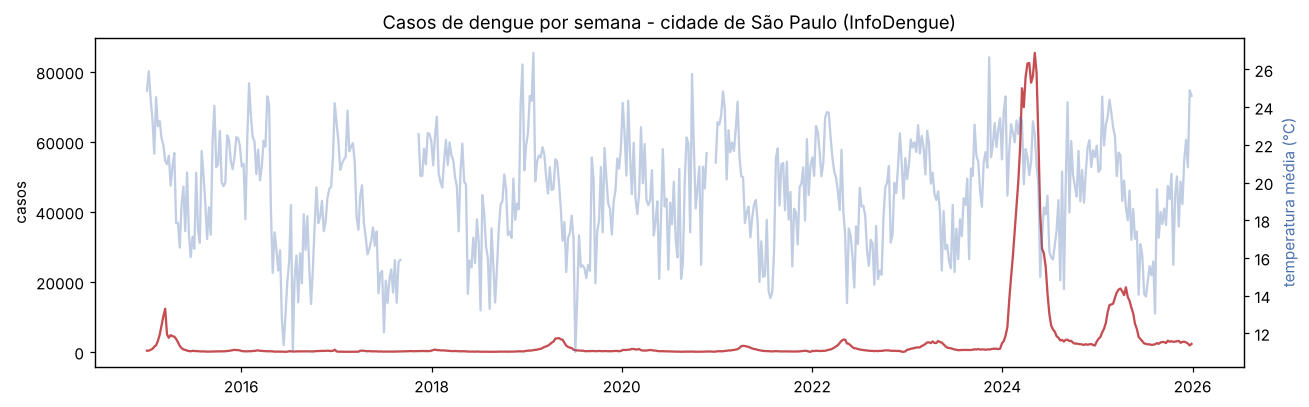

          casos      Rt  tempmed  umidmed
count    574.00  574.00   561.00   561.00
mean    3380.08    1.07    19.40    77.70
std    11275.61    0.44     2.89     7.04
min       38.00    0.14    11.01    46.55
25%      192.25    0.81    17.27    73.75
50%      401.00    0.99    19.75    78.84
75%     1921.50    1.21    21.53    82.73
max    85389.00    4.60    26.88    91.02


In [2]:
fig, eixo = plt.subplots(figsize=(12, 3.8))
eixo.plot(dados["data"], dados["casos"], color="#C44E52")
eixo.set_title("Casos de dengue por semana - cidade de São Paulo (InfoDengue)")
eixo.set_ylabel("casos")
eixo2 = eixo.twinx()
eixo2.plot(dados["data"], dados["tempmed"], color="#4C72B0", alpha=0.35)
eixo2.set_ylabel("temperatura média (°C)", color="#4C72B0")
plt.tight_layout(); plt.show()
print(dados[["casos", "Rt", "tempmed", "umidmed"]].describe().round(2))

Os surtos se repetem todo começo de ano, quando esquenta. A escala muda muito: de algumas dezenas de casos por semana no inverno até 85 mil no pico de 2024. Isso pesa nas decisões de preparação.

## 3. Preparação dos dados

Decisões principais:

1. **Valores faltando:** 13 semanas não têm temperatura média e umidades. Como é série temporal, preenchemos por **interpolação** entre a semana anterior e a seguinte, em vez de usar uma média geral.
2. **Log dos casos:** os casos variam de 38 a 85 mil. Usamos `log(1 + casos)` para a rede não ficar dominada pelos picos.
3. **Prever a variação, não o valor:** testamos primeiro prever o número de casos direto e a rede errou muito em 2024, porque nunca tinha visto valores tão altos no treino. A saída passou a ser **quanto o log dos casos vai subir ou cair** em relação à última semana conhecida. A dinâmica de um surto (crescer, chegar no pico, cair) é parecida em anos grandes e pequenos, e isso a rede consegue aprender.
4. **Atributos de entrada (8):** variação semanal do log dos casos, Rt, temperatura média, temperatura mínima, umidade média, umidade máxima e semana do ano em seno e cosseno.
5. **Janelas:** cada exemplo tem 12 semanas de entrada (cerca de 3 meses, o tempo de um surto ganhar força) e 4 semanas de saída.
6. **Divisão por tempo, sem embaralhar:** treino 2015-2021, validação 2022 e teste 2023-2025. O teste tem a epidemia de 2024, que a rede nunca viu.
7. **Padronização** (StandardScaler) ajustada **só com o treino**, para não vazar informação do futuro.

In [3]:
for coluna in ["tempmed", "umidmed", "umidmax"]:
    dados[coluna] = dados[coluna].interpolate(limit_direction="both")
dados["log_casos"] = np.log1p(dados["casos"])
dados["variacao_log"] = dados["log_casos"].diff().fillna(0)
semana = dados["SE"] % 100
dados["semana_sin"] = np.sin(2 * np.pi * semana / 52)
dados["semana_cos"] = np.cos(2 * np.pi * semana / 52)

ATRIBUTOS = ["variacao_log", "Rt", "tempmed", "tempmin", "umidmed", "umidmax", "semana_sin", "semana_cos"]
JANELA, HORIZONTE = 12, 4
fim_treino = dados.index[dados["data"] < "2022-01-01"].max()
fim_validacao = dados.index[dados["data"] < "2023-01-01"].max()

padronizador = StandardScaler().fit(dados.loc[:fim_treino, ATRIBUTOS])
Z = padronizador.transform(dados[ATRIBUTOS])
log_casos = dados["log_casos"].values

X, Y, inicio = [], [], []
for t in range(JANELA, len(dados) - HORIZONTE + 1):
    X.append(Z[t - JANELA:t])                          # 12 semanas de entrada
    Y.append(log_casos[t:t + HORIZONTE] - log_casos[t - 1])  # variação nas 4 semanas seguintes
    inicio.append(t)
X, Y, inicio = np.array(X, dtype="float32"), np.array(Y, dtype="float32"), np.array(inicio)
ultimo_log = log_casos[inicio - 1][:, None]

em_treino = inicio + HORIZONTE - 1 <= fim_treino
em_validacao = (inicio > fim_treino) & (inicio + HORIZONTE - 1 <= fim_validacao)
em_teste = inicio > fim_validacao
X_tr, Y_tr = X[em_treino], Y[em_treino]
X_va, Y_va = X[em_validacao], Y[em_validacao]
X_te, Y_te = X[em_teste], Y[em_teste]
print("Formato de X:", X.shape, "(exemplos, semanas, atributos) | Formato de Y:", Y.shape)
print(f"Treino: {len(X_tr)} janelas | Validação: {len(X_va)} | Teste: {len(X_te)}")
print("Exemplo de saída esperada (variação do log nas 4 semanas):", Y_tr[0].round(3))

Formato de X: (559, 12, 8) (exemplos, semanas, atributos) | Formato de Y: (559, 4)
Treino: 350 janelas | Validação: 49 | Teste: 154
Exemplo de saída esperada (variação do log nas 4 semanas): [-0.212 -0.039 -0.109 -0.131]


## 4. Arquitetura da rede

Escolhemos uma **RNN do tipo LSTM** (Long Short-Term Memory):

- Os dados são uma **sequência no tempo**: o que acontece nesta semana depende das anteriores. Uma MLP veria as 12 semanas como números soltos. Uma CNN serve melhor para imagens.
- A LSTM tem uma **memória interna com portões** (de esquecer, de entrada e de saída) que decidem o que guardar das semanas anteriores. Isso evita o problema da RNN simples, que esquece o começo de sequências longas.
- O efeito do clima na dengue tem **atraso**: o calor de hoje vira mosquito em 1 a 2 semanas e caso notificado depois. A LSTM consegue aprender esse atraso sozinha.

**Como a rede processa os dados:** ela lê as 12 semanas uma por uma. A cada semana atualiza o seu estado interno com os 8 atributos. No fim, o estado resume a situação (por exemplo, "o Rt subiu 3 semanas seguidas e está quente"). Uma camada **Dense** com 4 neurônios transforma esse resumo nas 4 variações previstas. Somando cada variação ao log dos casos da última semana e desfazendo o log, temos os casos previstos.

Estrutura base: `Entrada (12 semanas × 8 atributos) → LSTM → Dropout → Dense(4)`.

In [4]:
tf.keras.utils.set_random_seed(42)

def criar_rede(neuronios=32, dropout=0.0, camadas=1, taxa=1e-3):
    rede = tf.keras.Sequential([tf.keras.Input(shape=(JANELA, len(ATRIBUTOS)))], name="lstm_dengue")
    for i in range(camadas):
        rede.add(tf.keras.layers.LSTM(neuronios, return_sequences=i < camadas - 1))
        if dropout > 0:
            rede.add(tf.keras.layers.Dropout(dropout))
    rede.add(tf.keras.layers.Dense(HORIZONTE))
    rede.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=taxa), loss="mse", metrics=["mae"])
    return rede

criar_rede(32, 0.2).summary()

Model: "lstm_dengue"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,380 (21.02 KB)

 Trainable params: 5,380 (21.02 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Treinamento

Parâmetros do primeiro treino (configuração A, sem regularização):

| Parâmetro | Valor |
|---|---|
| Função de perda | MSE (erro quadrático médio) |
| Otimizador | Adam |
| Learning rate | 0,001 |
| Épocas | 300 |
| Batch size | 16 |
| Neurônios na LSTM | 32 |

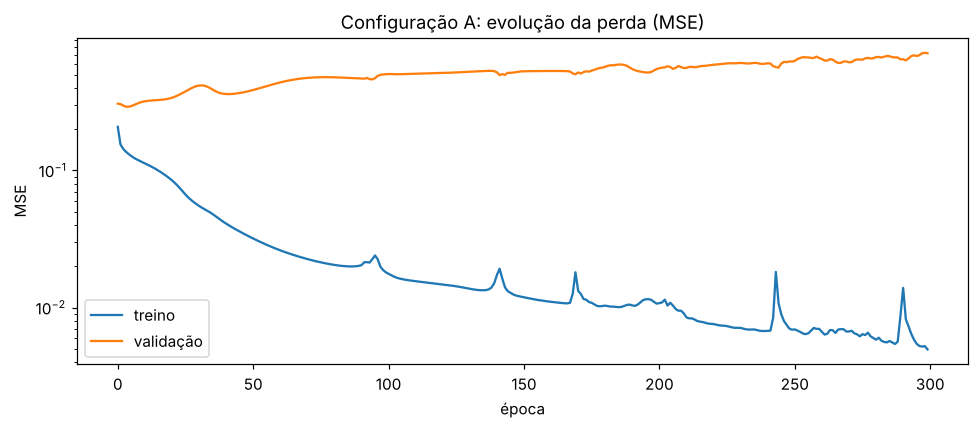

Menor perda de validação na época 4: 0.2916
Perda no fim (época 300): treino 0.0050 | validação 0.7155


In [5]:
def rmse_log(previsto, real):
    return float(np.sqrt(np.mean((previsto - real) ** 2)))

def casos(variacao, base_log):
    return np.expm1(base_log + variacao)

def avaliar(previsto, real, base_log):
    p, r = casos(previsto, base_log), casos(real, base_log)
    return {"RMSE (log)": rmse_log(previsto, real),
            "RMSE (casos)": float(np.sqrt(np.mean((p - r) ** 2))),
            "MAE (casos)": float(np.mean(np.abs(p - r)))}

tf.keras.utils.set_random_seed(42)
rede_a = criar_rede(32)
historico_a = rede_a.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=300, batch_size=16, verbose=0)

plt.figure(figsize=(9, 4))
plt.plot(historico_a.history["loss"], label="treino")
plt.plot(historico_a.history["val_loss"], label="validação")
plt.title("Configuração A: evolução da perda (MSE)"); plt.xlabel("época"); plt.ylabel("MSE"); plt.legend()
plt.yscale("log"); plt.tight_layout(); plt.show()
melhor_epoca = int(np.argmin(historico_a.history["val_loss"])) + 1
print(f"Menor perda de validação na época {melhor_epoca}: {min(historico_a.history['val_loss']):.4f}")
print(f"Perda no fim (época 300): treino {historico_a.history['loss'][-1]:.4f} | validação {historico_a.history['val_loss'][-1]:.4f}")

A perda de treino continua caindo até o fim, mas a de validação para de cair logo no começo e depois sobe. É **overfitting** clássico: a rede começa a decorar as semanas de treino e perde a capacidade de generalizar. O próximo passo é corrigir isso.

## 6. Refinamento e otimização

Problemas identificados no treino A: overfitting depois de poucas dezenas de épocas e dados com ruído (semanas com picos isolados de notificação).

Estratégias testadas, sempre comparando pela **validação** (2022) para não escolher olhando o teste:

| Config. | Neurônios | Camadas | Dropout | Learning rate | Batch | Early stopping |
|---|---|---|---|---|---|---|
| A | 32 | 1 | - | 0,001 | 16 | não |
| B | 32 | 1 | 0,2 | 0,001 | 16 | sim (paciência 25) |
| C | 64 | 1 | 0,3 | 0,001 | 16 | sim |
| D | 32 | 2 | 0,2 | 0,0005 | 16 | sim |
| E | 32 | 1 | 0,2 | 0,001 | 32 | sim |
| F | 16 | 1 | 0,2 | 0,001 | 16 | sim |

- **Dropout** desliga neurônios ao acaso durante o treino e obriga a rede a não depender de um caminho só.
- **Early stopping** para o treino quando a validação piora por 25 épocas seguidas e volta para os melhores pesos.
- Variamos **número de neurônios, de camadas, learning rate e batch size** para ver o efeito da capacidade da rede e do passo de aprendizado.

In [6]:
configuracoes = {
    "A": dict(neuronios=32, camadas=1, dropout=0.0, taxa=1e-3, batch=16, parar_cedo=False),
    "B": dict(neuronios=32, camadas=1, dropout=0.2, taxa=1e-3, batch=16, parar_cedo=True),
    "C": dict(neuronios=64, camadas=1, dropout=0.3, taxa=1e-3, batch=16, parar_cedo=True),
    "D": dict(neuronios=32, camadas=2, dropout=0.2, taxa=5e-4, batch=16, parar_cedo=True),
    "E": dict(neuronios=32, camadas=1, dropout=0.2, taxa=1e-3, batch=32, parar_cedo=True),
    "F": dict(neuronios=16, camadas=1, dropout=0.2, taxa=1e-3, batch=16, parar_cedo=True),
}
redes, historicos, linhas = {"A": rede_a}, {"A": historico_a}, []
for nome, cfg in configuracoes.items():
    if nome != "A":
        tf.keras.utils.set_random_seed(42)
        rede = criar_rede(cfg["neuronios"], cfg["dropout"], cfg["camadas"], cfg["taxa"])
        parada = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)] if cfg["parar_cedo"] else []
        historicos[nome] = rede.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=300,
                                    batch_size=cfg["batch"], verbose=0, callbacks=parada)
        redes[nome] = rede
    r_tr = avaliar(redes[nome].predict(X_tr, verbose=0), Y_tr, ultimo_log[em_treino])
    r_va = avaliar(redes[nome].predict(X_va, verbose=0), Y_va, ultimo_log[em_validacao])
    linhas.append({"config": nome, "épocas": len(historicos[nome].history["loss"]),
                   "RMSE log treino": r_tr["RMSE (log)"], "RMSE log validação": r_va["RMSE (log)"],
                   "MAE casos validação": r_va["MAE (casos)"]})
ingenuo_va = avaliar(np.zeros_like(Y_va), Y_va, ultimo_log[em_validacao])
linhas.append({"config": "Ingênuo (repete a última semana)", "épocas": 0, "RMSE log treino": np.nan,
               "RMSE log validação": ingenuo_va["RMSE (log)"], "MAE casos validação": ingenuo_va["MAE (casos)"]})
comparacao = pd.DataFrame(linhas).round(3)
comparacao

,config,épocas,RMSE log treino,RMSE log validação,MAE casos validação
0,A,300,0.071,0.846,478.787
1,B,28,0.378,0.547,279.363
2,C,27,0.375,0.531,274.392
3,D,27,0.388,0.535,293.579
4,E,30,0.376,0.550,281.519
5,F,28,0.405,0.555,305.774
6,Ingênuo (repete a última semana),0,NaN,0.561,349.163


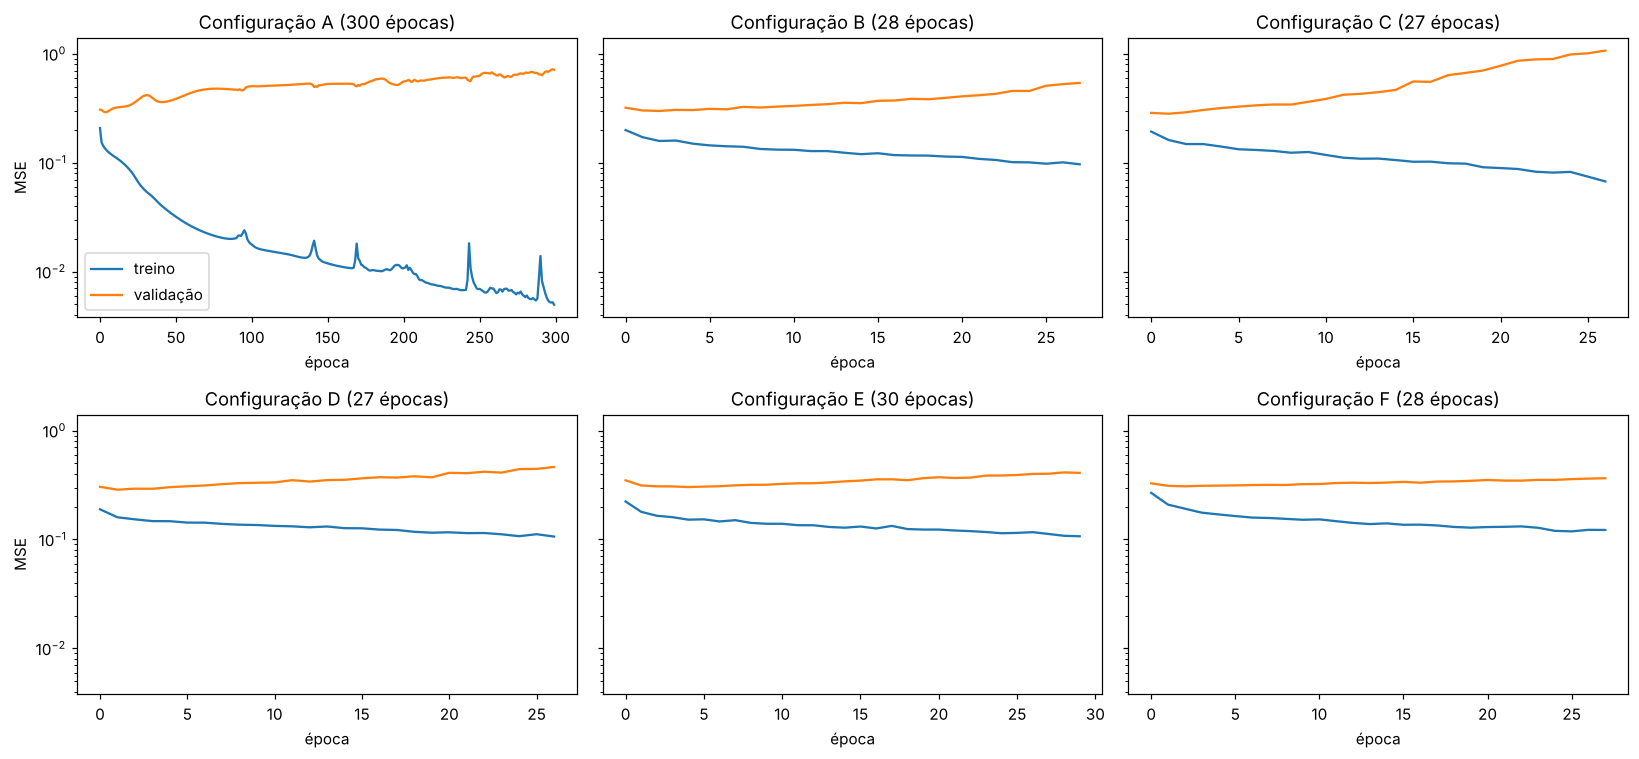

In [7]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for eixo, nome in zip(eixos.ravel(), configuracoes):
    h = historicos[nome].history
    eixo.plot(h["loss"], label="treino"); eixo.plot(h["val_loss"], label="validação")
    eixo.set_title(f"Configuração {nome} ({len(h['loss'])} épocas)"); eixo.set_yscale("log"); eixo.set_xlabel("época")
eixos[0, 0].set_ylabel("MSE"); eixos[1, 0].set_ylabel("MSE"); eixos[0, 0].legend()
plt.tight_layout(); plt.show()

In [8]:
candidatas = comparacao[comparacao["config"].isin(list("BCDEF"))]
escolhida = candidatas.sort_values("RMSE log validação").iloc[0]["config"]
rede_final = redes[escolhida]
print("Configuração escolhida pela validação:", escolhida, configuracoes[escolhida])
print(comparacao.set_index("config").loc[["A", escolhida, "Ingênuo (repete a última semana)"]])

Configuração escolhida pela validação: C {'neuronios': 64, 'camadas': 1, 'dropout': 0.3, 'taxa': 0.001, 'batch': 16, 'parar_cedo': True}
                                  épocas  RMSE log treino  RMSE log validação  \
config                                                                          
A                                    300            0.071               0.846   
C                                     27            0.375               0.531   
Ingênuo (repete a última semana)       0              NaN               0.561   

                                  MAE casos validação  
config                                                 
A                                             478.787  
C                                             274.392  
Ingênuo (repete a última semana)              349.163  


Com dropout e early stopping o treino para sozinho no ponto certo, e a perda de validação fica bem menor que a da configuração A. Com isso a rede deixa de decorar e passa a generalizar. A escolha final é feita pelo menor erro na **validação**: o teste só é usado uma vez, na próxima seção.

## 7. Avaliação no teste (2023-2025)

Métricas de regressão:

- **RMSE em log:** erro típico na escala do log. Um RMSE de 0,4 quer dizer errar, em geral, por um fator de cerca de 1,5 vezes para cima ou para baixo.
- **RMSE e MAE em casos:** erro em número de casos por semana, mais fácil de explicar. O RMSE pesa mais os erros grandes dos picos.
- Comparamos com o **modelo ingênuo** (as próximas 4 semanas iguais à última), que é o baseline de série temporal.

In [9]:
prev_te = rede_final.predict(X_te, verbose=0)
resultado = pd.DataFrame([
    {"modelo": f"LSTM (config. {escolhida})", **avaliar(prev_te, Y_te, ultimo_log[em_teste])},
    {"modelo": "LSTM (config. A, sem regularização)", **avaliar(rede_a.predict(X_te, verbose=0), Y_te, ultimo_log[em_teste])},
    {"modelo": "Ingênuo (repete a última semana)", **avaliar(np.zeros_like(Y_te), Y_te, ultimo_log[em_teste])},
]).round(3)
resultado

,modelo,RMSE (log),RMSE (casos),MAE (casos)
0,LSTM (config. C),0.385,6532.287,2854.260
1,"LSTM (config. A, sem regularização)",0.720,13220.701,5563.672
2,Ingênuo (repete a última semana),0.454,8133.796,3357.170


In [10]:
por_semana = []
for k in range(HORIZONTE):
    p = casos(prev_te[:, k], ultimo_log[em_teste][:, 0]); r = casos(Y_te[:, k], ultimo_log[em_teste][:, 0])
    i = casos(np.zeros(len(Y_te)), ultimo_log[em_teste][:, 0])
    por_semana.append({"semanas à frente": k + 1, "MAE LSTM": np.mean(np.abs(p - r)), "MAE ingênuo": np.mean(np.abs(i - r)),
                       "RMSE log LSTM": rmse_log(prev_te[:, k], Y_te[:, k]), "RMSE log ingênuo": rmse_log(np.zeros(len(Y_te)), Y_te[:, k])})
por_semana = pd.DataFrame(por_semana).round(2)
por_semana

,semanas à frente,MAE LSTM,MAE ingênuo,RMSE log LSTM,RMSE log ingênuo
0,1,1475.37,1570.40,0.20,0.22
1,2,2540.94,2783.61,0.33,0.36
2,3,3537.61,3949.97,0.43,0.50
3,4,3863.12,5124.69,0.51,0.63


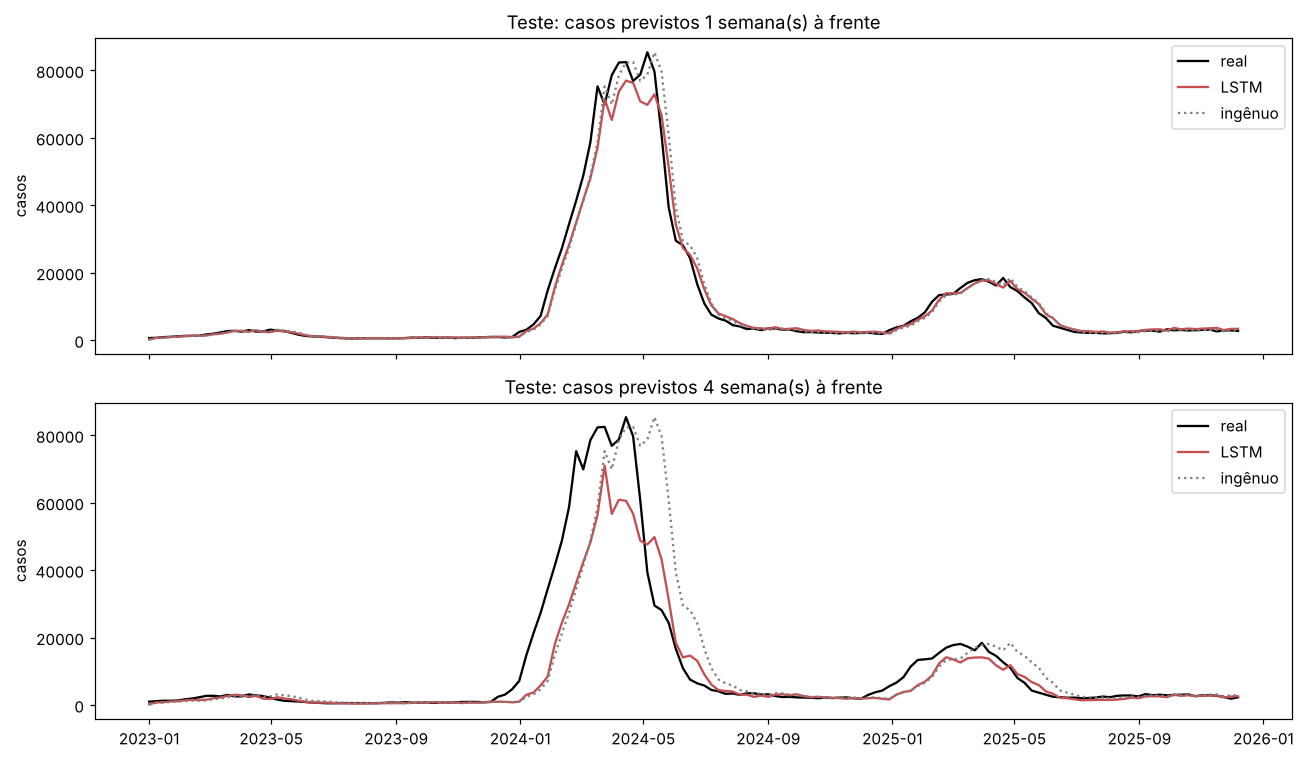

In [11]:
datas_te = dados["data"].values[inicio[em_teste]]
fig, eixos = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eixo, k in zip(eixos, [0, 3]):
    eixo.plot(datas_te, casos(Y_te[:, k], ultimo_log[em_teste][:, 0]), color="black", label="real")
    eixo.plot(datas_te, casos(prev_te[:, k], ultimo_log[em_teste][:, 0]), color="#C44E52", label="LSTM")
    eixo.plot(datas_te, casos(np.zeros(len(Y_te)), ultimo_log[em_teste][:, 0]), color="gray", ls=":", label="ingênuo")
    eixo.set_title(f"Teste: casos previstos {k + 1} semana(s) à frente"); eixo.set_ylabel("casos"); eixo.legend()
plt.tight_layout(); plt.show()

**Interpretação:**

- A LSTM regularizada erra menos que o modelo ingênuo em todos os horizontes, e a vantagem cresce quanto mais longe a previsão: 4 semanas à frente o erro médio cai de cerca de 5,1 mil para 3,9 mil casos por semana. Repetir a última semana funciona para amanhã, não para daqui a um mês.
- A configuração A, sem regularização, é a pior de todas no teste, quase o dobro do erro da escolhida. Isso confirma que o dropout e o early stopping melhoraram de verdade a generalização.
- **Pontos fortes:** a rede aprendeu a dinâmica do surto. Ela percebe quando o pico passou (Rt caindo, esfriando) e antecipa bem a queda dos casos.
- **Erros e limitações:** no começo de um surto ela atrasa a subida. Antes de o Rt disparar, as semanas de entrada parecem calmas e a rede prevê estabilidade. O erro em número de casos é grande nos picos (alguns milhares), porque 2024 foi muito maior que tudo no treino.
- **É adequado ao problema?** Sim, para o uso que propomos: mostrar a tendência das próximas semanas (subindo, estável, caindo) e a ordem de grandeza. Não serve para planejar leitos com precisão de unidades.

## 8. Demonstração com dados que a rede não viu no treino

Escolhemos duas semanas reais do período de teste: o fim do pico da epidemia de 2024 (maio) e a véspera da epidemia (dezembro de 2023). A entrada são as 12 semanas anteriores; a saída, os casos das 4 semanas seguintes.

In [12]:
def prever_proximas_semanas(data_ultima_semana):
    t = int(dados.index[dados["data"] == pd.Timestamp(data_ultima_semana)][0]) + 1
    janela = Z[t - JANELA:t][None, :, :].astype("float32")
    variacao = rede_final.predict(janela, verbose=0)[0]
    previsto = np.expm1(log_casos[t - 1] + variacao)
    datas = dados["data"].iloc[t:t + HORIZONTE].dt.date.values
    real = dados["casos"].iloc[t:t + HORIZONTE].values
    return pd.DataFrame({"semana": datas, "casos previstos": previsto.round(0).astype(int), "casos reais": real})

for data in ["2024-05-12", "2023-12-24"]:
    t = int(dados.index[dados["data"] == pd.Timestamp(data)][0])
    entrada = dados.iloc[t - 3:t + 1][["data", "casos", "Rt", "tempmed", "umidmed"]]
    print(f"\n=== Últimas semanas conhecidas (entrada, até {data}) ===")
    print(entrada.round(2).to_string(index=False))
    print("=== Previsão da LSTM para as 4 semanas seguintes ===")
    print(prever_proximas_semanas(data).to_string(index=False))


=== Últimas semanas conhecidas (entrada, até 2024-05-12) ===
      data  casos   Rt  tempmed  umidmed
2024-04-21  76880 0.96    21.12    78.79
2024-04-28  78759 0.98    23.25    68.38
2024-05-05  85389 1.08    22.58    67.96
2024-05-12  79706 1.00    20.94    70.37
=== Previsão da LSTM para as 4 semanas seguintes ===
    semana  casos previstos  casos reais
2024-05-19            66734        60783
2024-05-26            64544        39370
2024-06-02            52011        29522
2024-06-09            43198        28145

=== Últimas semanas conhecidas (entrada, até 2023-12-24) ===
      data  casos   Rt  tempmed  umidmed
2023-12-03    931 1.16    23.16    83.30
2023-12-10    938 1.07    21.88    82.83
2023-12-17    815 0.89    22.84    81.94
2023-12-24    942 1.05    23.41    75.52
=== Previsão da LSTM para as 4 semanas seguintes ===
    semana  casos previstos  casos reais
2023-12-31             1066         2456
2024-01-07             1163         3107
2024-01-14              920     

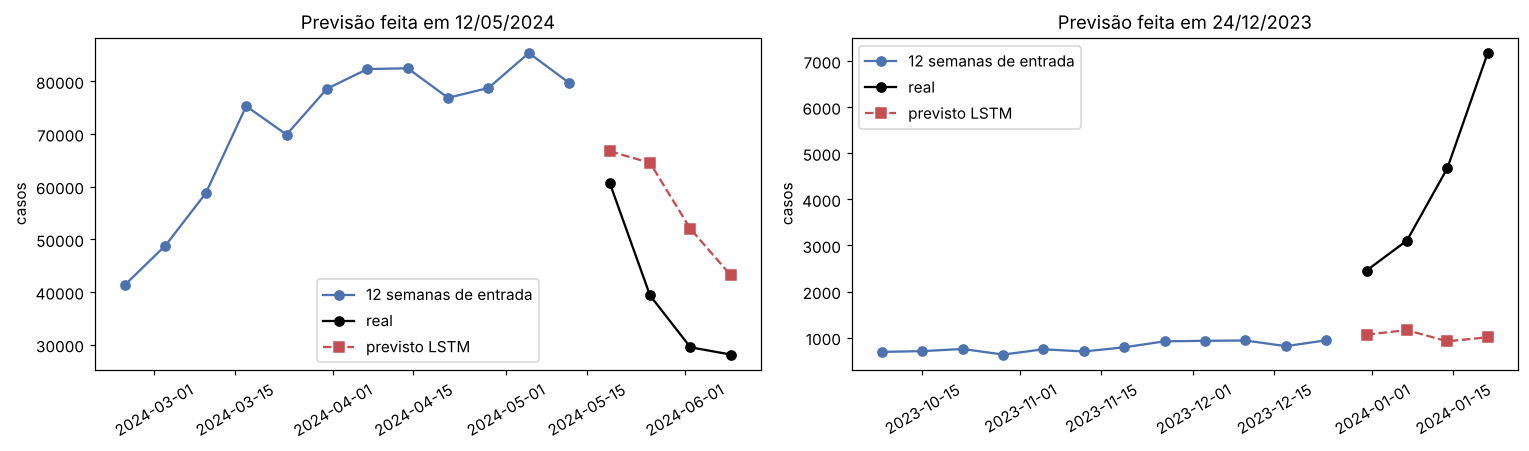

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.2))
for eixo, data in zip(eixos, ["2024-05-12", "2023-12-24"]):
    t = int(dados.index[dados["data"] == pd.Timestamp(data)][0])
    hist = dados.iloc[t - 11:t + 1]
    prev = prever_proximas_semanas(data)
    eixo.plot(hist["data"], hist["casos"], "o-", color="#4C72B0", label="12 semanas de entrada")
    eixo.plot(pd.to_datetime(prev["semana"]), prev["casos reais"], "o-", color="black", label="real")
    eixo.plot(pd.to_datetime(prev["semana"]), prev["casos previstos"], "s--", color="#C44E52", label="previsto LSTM")
    eixo.set_title(f"Previsão feita em {pd.Timestamp(data).strftime('%d/%m/%Y')}"); eixo.set_ylabel("casos"); eixo.legend()
    eixo.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**O que a demonstração mostra:** em 12/05/2024 a cidade tinha quase 80 mil casos na semana. A rede previu uma queda forte nas 4 semanas seguintes, e a queda aconteceu; o modelo ingênuo diria que continuaria igual. Já em 24/12/2023, véspera da epidemia recorde, a rede previu estabilidade e errou: os casos subiram de 942 para mais de 7 mil em 4 semanas. Por isso, no Alerta Criadouro, a previsão da LSTM não trabalha sozinha: o classificador de Machine Learning, que olha o Rt e a variação dos casos, avisou o risco alto já em 31/12/2023, e o aparelho no quintal continua avisando sempre que há água parada.

## 9. Integração com o Alerta Criadouro

A rede roda uma vez por semana, quando o InfoDengue publica os dados novos. O resultado vai para a API do projeto e aparece no app da família e no painel dos agentes de saúde. A função abaixo simula a mensagem que o app mostraria.

In [14]:
def resumo_para_app(data_ultima_semana):
    prev = prever_proximas_semanas(data_ultima_semana)
    t = int(dados.index[dados["data"] == pd.Timestamp(data_ultima_semana)][0])
    atual = dados["casos"].iloc[t]
    fim = prev["casos previstos"].iloc[-1]
    mudanca = (fim / atual - 1) * 100
    if mudanca > 25:
        tendencia = "SUBINDO. Faça a vistoria do quintal toda semana e fique de olho no seu Alerta Criadouro."
    elif mudanca < -25:
        tendencia = "CAINDO, mas não relaxe: água parada ainda vira mosquito em 10 dias."
    else:
        tendencia = "ESTÁVEL. Mantenha a vistoria semanal."
    return {"semana_base": data_ultima_semana, "casos_na_semana": int(atual),
            "previsao_4_semanas": prev["casos previstos"].tolist(),
            "mudanca_em_4_semanas_pct": round(float(mudanca), 1),
            "mensagem": f"Dengue em São Paulo: tendência {tendencia}"}

import json
print(json.dumps(resumo_para_app("2024-05-12"), ensure_ascii=False, indent=2))
print(json.dumps(resumo_para_app("2025-01-26"), ensure_ascii=False, indent=2))

{
  "semana_base": "2024-05-12",
  "casos_na_semana": 79706,
  "previsao_4_semanas": [
    66734,
    64544,
    52011,
    43198
  ],
  "mudanca_em_4_semanas_pct": -45.8,
  "mensagem": "Dengue em São Paulo: tendência CAINDO, mas não relaxe: água parada ainda vira mosquito em 10 dias."
}
{
  "semana_base": "2025-01-26",
  "casos_na_semana": 6639,
  "previsao_4_semanas": [
    7085,
    7226,
    6394,
    6915
  ],
  "mudanca_em_4_semanas_pct": 4.2,
  "mensagem": "Dengue em São Paulo: tendência ESTÁVEL. Mantenha a vistoria semanal."
}


In [15]:
rede_final.save("lstm_casos_dengue.keras")
print("Rede salva em lstm_casos_dengue.keras")

Rede salva em lstm_casos_dengue.keras


**Integração real com a API do projeto:** a rede já está ligada ao sistema. A API em Flask do Alerta Criadouro tem a rota `GET /previsao` (arquivo `api/previsao.py`), que junta a última leitura do quintal enviada pelo ESP32, o risco da próxima semana dado pelo modelo de Machine Learning e a previsão de casos das próximas 4 semanas feita por esta LSTM, com a mesma configuração escolhida aqui (configuração C). A resposta traz a mensagem pronta para a família.

Teste feito pela internet, com a API no Google Colab, em 06/11/2026: a rota respondeu HTTP 200 com 2.645, 2.680, 2.289 e 2.448 casos previstos para as semanas de janeiro de 2026, tendência estável, e a mensagem "Seu potinho está com água há dias: esvazie os vasos, baldes e pratinhos do quintal hoje" para um quintal em ALERTA.

**Evoluções futuras:**
- baixar os dados novos do InfoDengue toda semana de forma automática;
- previsão por bairro, quando houver dados por região, usando também as leituras dos aparelhos Alerta Criadouro;
- usar a previsão do tempo das próximas semanas como entrada.

**Acessibilidade, segurança e uso real:** a mensagem usa linguagem simples e cores de semáforo; a rota pede o token do aparelho; a base é conferida por hash antes de cada treino; a rede usa só dados abertos da cidade inteira, sem nenhum dado pessoal das famílias; e o modelo é pequeno o bastante para rodar num servidor barato.